<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/deep-learning/pretrained_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**LeNet - Pretrained model**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from keras.datasets import mnist
from keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
data = tf.keras.datasets.fashion_mnist.load_data()

In [ ]:
(x_train,y_train),(x_test,y_test) = data

In [ ]:
(x_train,y_train),(x_val,y_val) = data

In [ ]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

In [ ]:
print(x_train.shape)

(60000, 28, 28)


In [ ]:
print(y_train.shape)

(60000,)


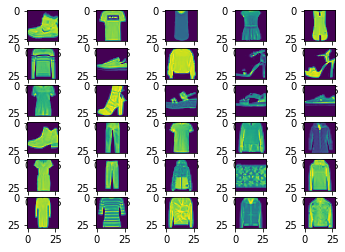

In [ ]:
for i in range(30):
  plt.subplot(6,5 , 1 + i)
  plt.imshow(x_train[i])

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(filters=6,input_shape=(28,28,1), kernel_size=(5,5),strides=(1,1), padding='same', activation='tanh'),
    tf.keras.layers.AveragePooling2D(2,2),
    tf.keras.layers.Conv2D(filters=16, kernel_size=(5,5), activation='tanh'),
    tf.keras.layers.AveragePooling2D(2,2),
    tf.keras.layers.Conv2D(filters=120, kernel_size=(5,5), activation='tanh'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(84, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax')
])


In [ ]:
model.compile(optimizer = 'adam',
              loss = 'sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
history = model.fit(x_train,y_train)

1875/1875 [==============================] - 48s 25ms/step - loss: 0.2113 - accuracy: 0.9207


In [ ]:
model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_21 (Conv2D)          (None, 28, 28, 6)         156       
                                                                 
 average_pooling2d_14 (Avera  (None, 14, 14, 6)        0         
 gePooling2D)                                                    
                                                                 
 conv2d_22 (Conv2D)          (None, 10, 10, 16)        2416      
                                                                 
 average_pooling2d_15 (Avera  (None, 5, 5, 16)         0         
 gePooling2D)                                                    
                                                                 
 conv2d_23 (Conv2D)          (None, 1, 1, 120)         48120     
                                                                 
 flatten_7 (Flatten)         (None, 120)              

In [ ]:
print(model.evaluate(x_test,y_test))

313/313 [==============================] - 4s 13ms/step - loss: 0.2760 - accuracy: 0.9013
[0.2759678065776825, 0.9013000130653381]


313/313 [==============================] - 4s 12ms/step
2


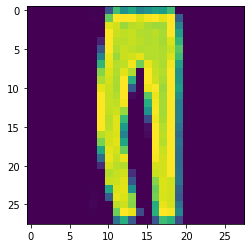

In [ ]:
plt.imshow(x_test[2])
prediction=model.predict(x_test)
print(np.argmax(prediction[1]))

In [ ]:
pred_train= model.predict(x_train)
scores = model.evaluate(x_train, y_train, verbose=0)
print('Accuracy on training data: {}% \n Error on training data: {}'.format(scores[1], 1 - scores[1]))
pred_test= model.predict(x_test)
scores2 = model.evaluate(x_test, y_test, verbose=0)
acc=scores2[1]
loss = 1- scores2[1]
print('Accuracy on test data: {}% \n Error on test data: {}'.format(scores2[1], 1 - scores2[1]))

1875/1875 [==============================] - 23s 12ms/step
Accuracy on training data: 0.9247333407402039% 
 Error on training data: 0.07526665925979614
313/313 [==============================] - 4s 13ms/step
Accuracy on test data: 0.8934999704360962% 
 Error on test data: 0.10650002956390381


In [ ]:
#model1 = model.fit(x_train,y_train,validation_data = (x_val,y_val))

In [ ]:
#plt.xlabel("epoch")
#plt.ylabel("loss")
#plt.plot(model1.history["loss"])
#plt.plot(model1.history["val_loss"])
#plt.legend(['train', 'Validation'], loc='upper right')
#plt.show()

In [ ]:
#import matplotlib.pyplot as plt
#acc = history.history['accuracy']
#val_acc = history.history['val_accuracy']
#loss = history.history['loss']
#val_loss = history.history['val_loss']

#epochs = range(len(acc))
#plt.figure()
#plt.plot(epochs, acc, 'r', label='Training accuracy')
#plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
#plt.title('Training and validation accuracy')
#plt.legend()
#plt.figure()

#plt.plot(epochs, loss, 'r', label='Training Loss')
#plt.plot(epochs, val_loss, 'b', label='Validation Loss')
#plt.title('Training and validation loss')
#plt.legend()

#plt.show()